# Parametric Last Library — ANSUR II Regression Analysis
**Project:** Parametric footwear last driven by population anthropometric data
**Data:** ANSUR II (US Army, 2012) — 4,082 male / 1,986 female subjects
**Goal:** Derive regression equations relating foot length to key last dimensions, then generate the Creo relations and family table that drive a parametric last.

**Pipeline:** ANSUR II → OLS regressions on foot length → width grades from residuals → foot-to-last allowances → `creo/relations.txt` + `creo/family_table.csv` → Creo Parametric model.

## 1. Load data

In [1]:
import os
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs('../figures', exist_ok=True)
os.makedirs('../creo', exist_ok=True)

# Load ANSUR II data (download from the ANSUR II public release; place both CSVs in ../data/)
male = pd.read_csv('../data/ANSUR_II_MALE_Public.csv', encoding='latin-1')
female = pd.read_csv('../data/ANSUR_II_FEMALE_Public.csv', encoding='latin-1')

# Key foot variables for last construction (all in mm)
foot_vars = ['footlength', 'footbreadthhorizontal', 'balloffootcircumference',
             'heelbreadth', 'heelanklecircumference', 'balloffootlength']

# Plot colors (validated colorblind-safe set)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRAY = '#52514e'

print(f"Male: {male.shape} | Female: {female.shape}")
print(male[foot_vars].describe().loc[['mean', 'std', 'min', 'max']].round(1))

Male: (4082, 108) | Female: (1986, 108)
      footlength  footbreadthhorizontal  balloffootcircumference  heelbreadth  \
mean       271.2                  101.9                    252.0         72.5   
std         13.1                    5.2                     12.9          5.5   
min        216.0                   79.0                    186.0         48.0   
max        323.0                  126.0                    306.0         93.0   

      heelanklecircumference  balloffootlength  
mean                   343.5             200.9  
std                     16.6              10.5  
min                    258.0             156.0  
max                    403.0             245.0  


## 2. Regressions: foot length → foot dimensions
One simple linear regression per dimension, fit separately for each sex.
Heel-ankle girth (the diagonal girth around the heel and instep) replaces ankle circumference: it is the girth last makers use for heel fit, while ankle circumference sits above the shoe.

In [2]:
# The 5 dimensions we want to predict from foot length
targets = {
    'ball_width':       'footbreadthhorizontal',
    'ball_girth':       'balloffootcircumference',
    'heel_breadth':     'heelbreadth',
    'heel_ankle_girth': 'heelanklecircumference',
    'ball_length':      'balloffootlength',
}

def run_regressions(df, sex_label):
    rows = []
    for name, col in targets.items():
        r = stats.linregress(df['footlength'], df[col])
        rows.append({
            'sex': sex_label,
            'dimension': name,
            'slope': round(r.slope, 4),
            'intercept': round(r.intercept, 2),
            'r_squared': round(r.rvalue**2, 3),
        })
    return rows

coef_table = pd.DataFrame(run_regressions(male, 'M') + run_regressions(female, 'F'))
coef_table.to_csv('../data/last_regression_coefficients.csv', index=False)
print(coef_table.to_string(index=False))

sex        dimension  slope  intercept  r_squared
  M       ball_width 0.2352      38.09      0.347
  M       ball_girth 0.5895      92.15      0.357
  M     heel_breadth 0.2019      17.74      0.234
  M heel_ankle_girth 1.0067      70.49      0.630
  M      ball_length 0.7393       0.46      0.856
  F       ball_width 0.2134      40.16      0.308
  F       ball_girth 0.5732      86.94      0.367
  F     heel_breadth 0.2137      14.53      0.264
  F heel_ankle_girth 0.9883      66.90      0.645
  F      ball_length 0.7286       2.61      0.883


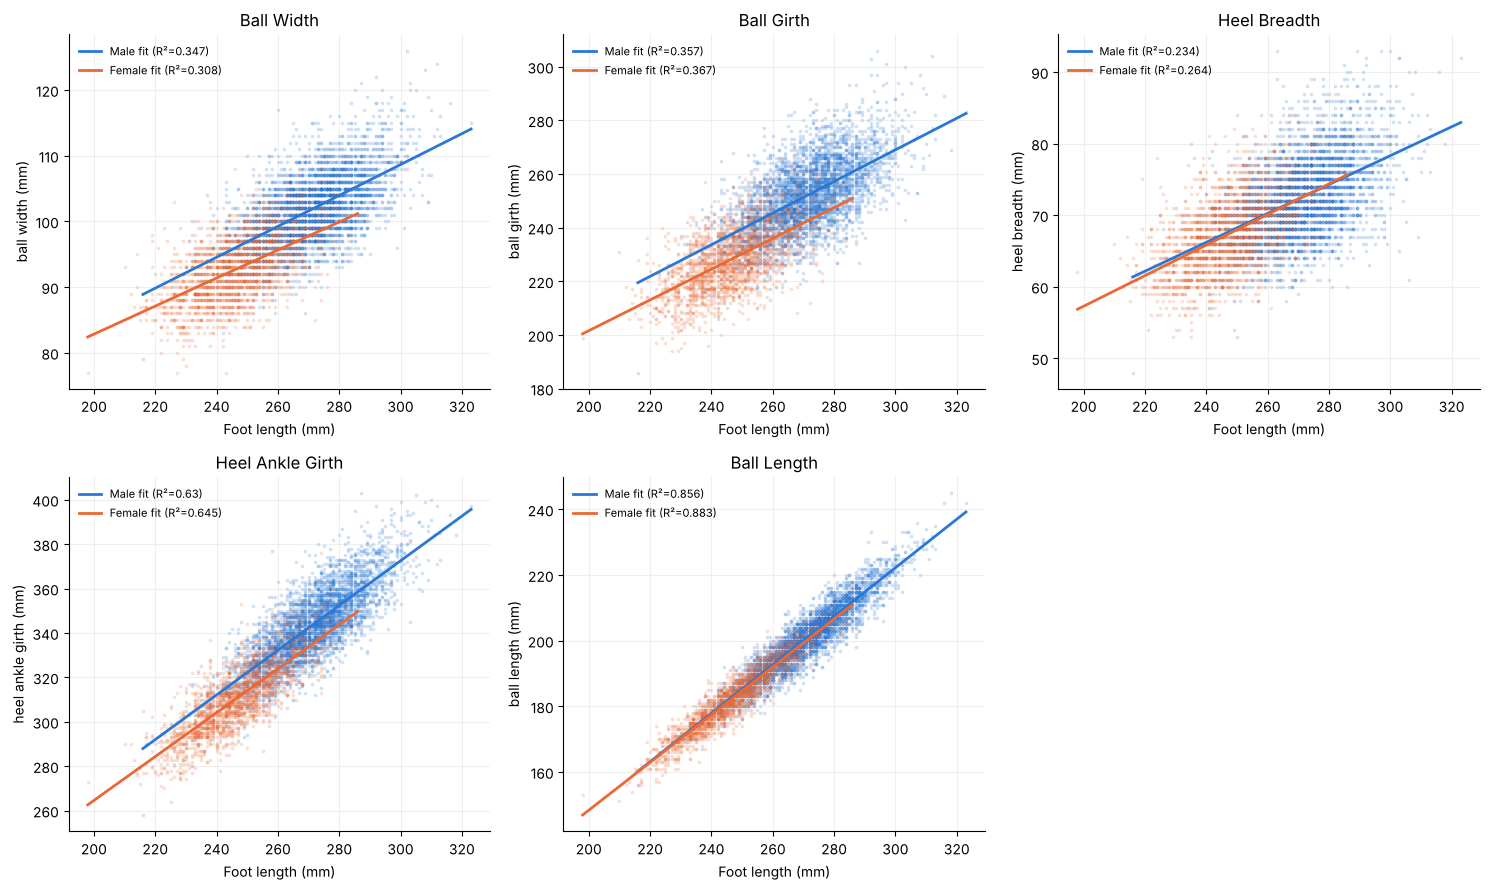

In [3]:
# Grid of regression plots, one per dimension, male vs female overlaid
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, col) in enumerate(targets.items()):
    ax = axes[i]
    for df, sex, color in [(male, 'M', BLUE), (female, 'F', ORANGE)]:
        label = 'Male' if sex == 'M' else 'Female'
        ax.scatter(df['footlength'], df[col], s=3, alpha=0.15, color=color)
        row = coef_table[(coef_table['sex'] == sex) & (coef_table['dimension'] == name)].iloc[0]
        # Fit line drawn only across that population's real foot-length range
        x_line = np.linspace(df['footlength'].min(), df['footlength'].max(), 100)
        ax.plot(x_line, row['slope'] * x_line + row['intercept'], color=color, linewidth=2,
                label=f"{label} fit (R²={row['r_squared']})")
    ax.set_title(name.replace('_', ' ').title())
    ax.set_xlabel('Foot length (mm)')
    ax.set_ylabel(f'{name.replace("_", " ")} (mm)')
    ax.legend(fontsize=8, frameon=False)
    ax.grid(alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)

axes[5].axis('off')
plt.tight_layout()
plt.savefig('../figures/last_regressions.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Width grades from the residuals
Foot length explains ~86% of ball length but only ~35% of ball girth. Two men with the same foot length can differ by 30+ mm in ball girth, so length-scaling alone would fit only the average foot. Instead, the last gets a second input, `WIDTH_GRADE`.

**Method (men's, the first family table):**
1. Take each subject's ball-girth residual (actual − predicted from foot length).
2. Split the population into thirds by residual: narrow (B), medium (D), wide (2E). Each width then fits one third of men.
3. Each grade's offset is the median residual within its third. `GIRTH_STEP` is the average spacing between grades.
4. Ball width is graded by the same split, so one `WIDTH_GRADE` moves girth and width together, as they move together in real feet.

In [4]:
def fit(df, col):
    r = stats.linregress(df['footlength'], df[col])
    return df[col] - (r.slope * df['footlength'] + r.intercept)

g = pd.DataFrame({
    'girth_resid': fit(male, 'balloffootcircumference'),
    'width_resid': fit(male, 'footbreadthhorizontal'),
})

cuts = g['girth_resid'].quantile([1/3, 2/3]).values
g['grade'] = np.select([g['girth_resid'] < cuts[0], g['girth_resid'] < cuts[1]], [1, 2], default=3)

grade_names = {1: 'B (narrow)', 2: 'D (medium)', 3: '2E (wide)'}
grade_table = g.groupby('grade').agg(
    share=('girth_resid', lambda s: len(s) / len(g)),
    girth_offset=('girth_resid', 'median'),
    width_offset=('width_resid', 'median'),
).round(2)
grade_table.index = grade_table.index.map(grade_names)

GIRTH_STEP = round((grade_table['girth_offset'].iloc[2] - grade_table['girth_offset'].iloc[0]) / 2, 1)
WIDTH_STEP = round((grade_table['width_offset'].iloc[2] - grade_table['width_offset'].iloc[0]) / 2, 1)
r_gw = np.corrcoef(g['girth_resid'], g['width_resid'])[0, 1]

print(grade_table.to_string())
print(f"\nTertile cut points (girth residual): {cuts.round(1)} mm")
print(f"GIRTH_STEP = {GIRTH_STEP} mm per width grade")
print(f"WIDTH_STEP = {WIDTH_STEP} mm per width grade")
print(f"Girth/width residual correlation: r = {r_gw:.2f}")

# Context: girth change per full US size from the regression (1 size = 1/3 inch = 8.47 mm of length)
m_girth_slope = coef_table.query("sex=='M' and dimension=='ball_girth'")['slope'].iloc[0]
print(f"Girth change per full size from regression: {m_girth_slope * 25.4 / 3:.1f} mm")

            share  girth_offset  width_offset
grade                                        
B (narrow)   0.33         -9.75         -3.64
D (medium)   0.33         -0.31         -0.11
2E (wide)    0.33          9.93          3.42

Tertile cut points (girth residual): [-4.7  4.2] mm
GIRTH_STEP = 9.8 mm per width grade
WIDTH_STEP = 3.5 mm per width grade
Girth/width residual correlation: r = 0.80
Girth change per full size from regression: 5.0 mm


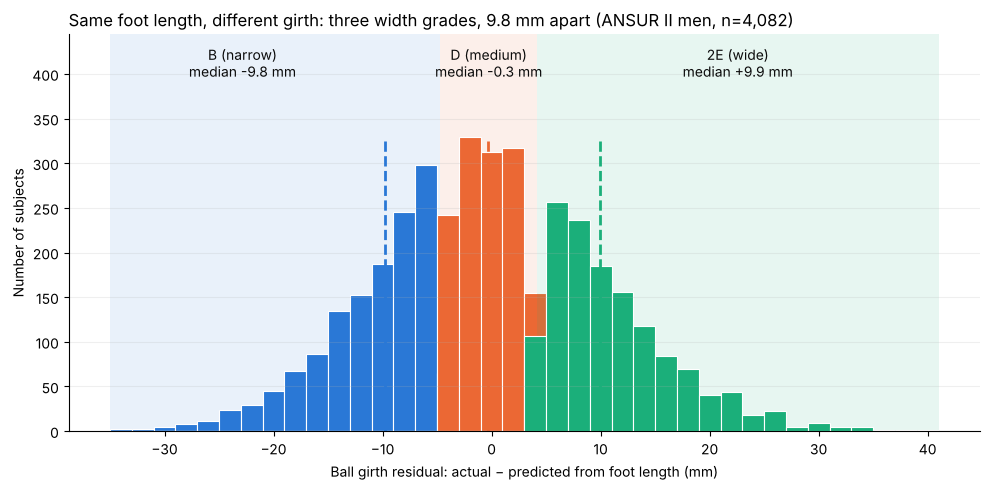

In [5]:
# Residual histogram with the three width grades shaded
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(np.floor(g['girth_resid'].min()), np.ceil(g['girth_resid'].max()) + 2, 2)
lo, hi = bins[0], bins[-1]
counts, _ = np.histogram(g['girth_resid'], bins=bins)
top = counts.max() * 1.35
label_x = [(-35 + cuts[0]) / 2 - 3, (cuts[0] + cuts[1]) / 2, (cuts[1] + 35) / 2 + 3]
spans = [(lo, cuts[0]), (cuts[0], cuts[1]), (cuts[1], hi)]
for (a, b), color, grade, lx in zip(spans, [BLUE, ORANGE, AQUA], [1, 2, 3], label_x):
    ax.axvspan(a, b, color=color, alpha=0.10, lw=0)
    sub = g.loc[g['grade'] == grade, 'girth_resid']
    ax.hist(sub, bins=bins, color=color, edgecolor='white', linewidth=0.8)
    ax.axvline(sub.median(), color=color, lw=2, ls='--', ymax=0.74)
    ax.text(lx, top * 0.97, f"{grade_names[grade]}\nmedian {sub.median():+.1f} mm",
            ha='center', va='top', fontsize=10, color='#0b0b0b')
ax.set_ylim(0, top)
ax.set_xlabel('Ball girth residual: actual − predicted from foot length (mm)')
ax.set_ylabel('Number of subjects')
ax.set_title(f"Same foot length, different girth: three width grades, {GIRTH_STEP} mm apart "
             f"(ANSUR II men, n={len(g):,})", loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.savefig('../figures/width_grades.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Foot-to-last allowances, calibrated on commercial running shoes
The regressions describe **feet**. A last is the form a shoe is built around, so it differs from the foot in a few deliberate ways. Instead of assuming those differences, they are measured on five current men's running shoes (October 2026, tape measure, 1/16"–1/32" resolution):

| Allowance | How it was measured |
|---|---|
| Toe allowance | Sockliner length − foot length for the shoe's US size |
| Bottom width factor | Sockliner width at the ball (flattened, measured straight across) ÷ the model's D-width ball width at that size |
| Drop | Published heel-to-toe drop |
| Toe spring | Shoe resting unloaded on a table; height from the table to the lowest point of the sole at the toe tip, read with a card held level against a vertical tape |

Each allowance is the **median** across shoes, so one unusual shoe cannot pull the value.

The On Cloudsurfer 3 has a pronounced rocker sole, so its toe spring is checked before use: it is included only if it falls inside the standard outlier fences (1.5 × IQR) of the toe spring values. Toe spring is measured on finished shoes, which includes some midsole curvature, so it likely overstates the last's toe spring slightly.

`GIRTH_EASE` is not measurable from a sockliner and stays at 0 (a snug performance fit).

In [6]:
def us_mens_to_foot_length(size):
    # Brannock-style rule: size = 3 x foot length (in) - 22
    return round((size + 22) / 3 * 25.4, 1)

def inches(s):
    # '12 2/16' -> mm
    whole, _, frac = s.partition(' ')
    value = float(whole) + (eval(frac) if frac else 0)
    return value * 25.4

shoes = pd.DataFrame([
    # model,                us size, sockliner length, sockliner ball width, toe spring, drop mm, rocker
    ('On Cloudsurfer 3',     12.5, '12 3/16',  '4 1/16',  '1 14/16', 8,  True),
    ('Saucony Ride 19',      11.0, '11 11/16', '4 4/32',  '1 5/8',   8,  False),
    ('Brooks Ghost 18',      10.0, '11 6/16',  '3 25/32', '1 7/16',  10, False),
    ('Asics Novablast 6',    11.5, '12 2/16',  '4 1/32',  '1 3/4',   8,  False),
    ('Hoka Clifton 11',      10.5, '11 9/16',  '3 30/32', '1 21/32', 8,  False),
], columns=['shoe', 'us_size', 'length_in', 'width_in', 'toe_spring_in', 'drop_mm', 'rocker'])

ball_width_D = coef_table.query("sex=='M' and dimension=='ball_width'").iloc[0]
shoes['foot_length'] = shoes['us_size'].apply(us_mens_to_foot_length)
shoes['toe_allowance'] = shoes['length_in'].apply(inches) - shoes['foot_length']
shoes['width_factor'] = shoes['width_in'].apply(inches) / (ball_width_D['slope'] * shoes['foot_length'] + ball_width_D['intercept'])
shoes['toe_spring'] = shoes['toe_spring_in'].apply(inches)

print(shoes[['shoe', 'us_size', 'foot_length', 'toe_allowance', 'width_factor', 'drop_mm', 'toe_spring', 'rocker']]
      .round({'toe_allowance': 1, 'width_factor': 3, 'toe_spring': 1}).to_string(index=False))

             shoe  us_size  foot_length  toe_allowance  width_factor  drop_mm  toe_spring  rocker
 On Cloudsurfer 3     12.5        292.1           17.5         0.966        8        47.6    True
  Saucony Ride 19     11.0        279.4           17.5         1.009        8        41.3   False
  Brooks Ghost 18     10.0        270.9           18.0         0.943       10        36.5   False
Asics Novablast 6     11.5        283.6           24.4         0.977        8        44.4   False
  Hoka Clifton 11     10.5        275.2           18.5         0.973        8        42.1   False


In [7]:
# Rocker-sole check: keep a rocker shoe's toe spring only if it is inside 1.5 x IQR fences
q1, q3 = shoes['toe_spring'].quantile([0.25, 0.75])
lo_fence, hi_fence = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
shoes['use_toe_spring'] = ~shoes['rocker'] | shoes['toe_spring'].between(lo_fence, hi_fence)
for _, s in shoes[shoes['rocker']].iterrows():
    verdict = 'included' if s['use_toe_spring'] else 'excluded as an outlier'
    print(f"{s['shoe']}: toe spring {s['toe_spring']:.1f} mm, fences {lo_fence:.1f}-{hi_fence:.1f} mm -> {verdict}")
n_ts = int(shoes['use_toe_spring'].sum())

ALLOWANCES = {
    'TOE_ALLOWANCE': round(shoes['toe_allowance'].median(), 1),                          # mm, median of all shoes
    'GIRTH_EASE': 0.0,                                                                   # mm, not measured: snug fit
    'BOTTOM_WIDTH_FACTOR': round(shoes['width_factor'].median(), 2),                     # ratio, median of all shoes
    'HEEL_HEIGHT': float(shoes['drop_mm'].median()),                                     # mm, median published drop
    'TOE_SPRING': round(shoes.loc[shoes['use_toe_spring'], 'toe_spring'].median(), 1),   # mm, median of n_ts shoes
}
print(f"\nShoes measured: {len(shoes)} | used for toe spring: {n_ts}")
pd.Series(ALLOWANCES, name='value')

On Cloudsurfer 3: toe spring 47.6 mm, fences 36.5-49.2 mm -> included

Shoes measured: 5 | used for toe spring: 5


TOE_ALLOWANCE          18.00
GIRTH_EASE              0.00
BOTTOM_WIDTH_FACTOR     0.97
HEEL_HEIGHT             8.00
TOE_SPRING             42.10
Name: value, dtype: float64

## 5. Generate the Creo relations
Each relation is written once, in Creo syntax, and used twice: written to `creo/relations.txt` for Creo, and evaluated in Python to compute target dimensions for every instance (Section 6). That guarantees the Python targets and the Creo model use identical equations.

**Inputs** (`FOOT_LENGTH`, `WIDTH_GRADE`) are never assigned in the relations; they come from the family table.

In [8]:
M = coef_table[coef_table['sex'] == 'M'].set_index('dimension')

def lin(dim):
    # "slope*FOOT_LENGTH + intercept" for one male regression
    r = M.loc[dim]
    return f"{r['slope']}*FOOT_LENGTH + {r['intercept']}"

# (parameter, Creo expression, comment) in evaluation order
allowance_notes = {
    'TOE_ALLOWANCE': 'allowance: extra length past the longest toe',
    'GIRTH_EASE': 'allowance: last ball girth minus foot ball girth (not measured; 0 = snug fit)',
    'BOTTOM_WIDTH_FACTOR': 'allowance: last bottom width / foot width',
    'HEEL_HEIGHT': 'allowance: heel-to-toe drop',
    'TOE_SPRING': 'allowance: toe lift off the ground plane',
}
RELATIONS = [(k, str(v), allowance_notes[k] + ('' if k == 'GIRTH_EASE' else ' (measured on 5 shoes, notebook Section 4)')) for k, v in ALLOWANCES.items()] + [
    ('GIRTH_STEP', str(GIRTH_STEP), 'ball girth change per width grade (girth residual tertiles)'),
    ('WIDTH_STEP', str(WIDTH_STEP), 'ball width change per width grade (same split)'),
    ('LAST_LENGTH', 'FOOT_LENGTH + TOE_ALLOWANCE', 'heel to toe tip of the last'),
    ('BALL_LENGTH', lin('ball_length'), f"heel to ball station, R^2 = {M.loc['ball_length','r_squared']}"),
    ('BALL_GIRTH', f"{lin('ball_girth')} + (WIDTH_GRADE - 2)*GIRTH_STEP + GIRTH_EASE",
     f"ball girth target, R^2 = {M.loc['ball_girth','r_squared']} before grading"),
    ('BALL_WIDTH', f"{lin('ball_width')} + (WIDTH_GRADE - 2)*WIDTH_STEP",
     f"max width at the ball, R^2 = {M.loc['ball_width','r_squared']} before grading"),
    ('BOTTOM_BALL_WIDTH', 'BALL_WIDTH*BOTTOM_WIDTH_FACTOR', 'last bottom width at the ball'),
    ('HEEL_WIDTH', lin('heel_breadth'), f"heel breadth, R^2 = {M.loc['heel_breadth','r_squared']}"),
    ('BOTTOM_HEEL_WIDTH', 'HEEL_WIDTH*BOTTOM_WIDTH_FACTOR', 'last bottom width at the heel'),
    ('HEEL_ANKLE_GIRTH', lin('heel_ankle_girth'),
     f"heel-ankle girth target, R^2 = {M.loc['heel_ankle_girth','r_squared']}"),
]

lines = [
    '/* Parametric last relations (men), generated by AO_Biomech.ipynb on ' + str(date.today()),
    '/* Source: ANSUR II male, n = %d, OLS regressions on foot length. Units: mm' % len(male),
    '/* INPUTS from family table (do not assign here):',
    '/*   FOOT_LENGTH  real, mm',
    '/*   WIDTH_GRADE  integer, 1 = B narrow, 2 = D medium, 3 = 2E wide',
    '',
]
for name, expr, comment in RELATIONS:
    lines += ['/* ' + comment, f'{name} = {expr}', '']
relations_txt = '\n'.join(lines)

with open('../creo/relations.txt', 'w', newline='\r\n') as f:  # Windows line endings for Notepad on the VDI
    f.write(relations_txt)

# Parameter list for Tools > Parameters (create these before pasting the relations)
params = [('FOOT_LENGTH', 'Real Number', 270.0, 'input (family table)'),
          ('WIDTH_GRADE', 'Integer', 2, 'input (family table)')]
params += [(name, 'Real Number', 0.0, 'driven by relations') for name, _, _ in RELATIONS]
param_table = pd.DataFrame(params, columns=['name', 'type', 'start_value', 'role'], dtype=object)
param_table.to_csv('../creo/parameters.csv', index=False)

print(relations_txt)

/* Parametric last relations (men), generated by AO_Biomech.ipynb on 2026-10-11
/* Source: ANSUR II male, n = 4082, OLS regressions on foot length. Units: mm
/* INPUTS from family table (do not assign here):
/*   FOOT_LENGTH  real, mm
/*   WIDTH_GRADE  integer, 1 = B narrow, 2 = D medium, 3 = 2E wide

/* allowance: extra length past the longest toe (measured on 5 shoes, notebook Section 4)
TOE_ALLOWANCE = 18.0

/* allowance: last ball girth minus foot ball girth (not measured; 0 = snug fit)
GIRTH_EASE = 0.0

/* allowance: last bottom width / foot width (measured on 5 shoes, notebook Section 4)
BOTTOM_WIDTH_FACTOR = 0.97

/* allowance: heel-to-toe drop (measured on 5 shoes, notebook Section 4)
HEEL_HEIGHT = 8.0

/* allowance: toe lift off the ground plane (measured on 5 shoes, notebook Section 4)
TOE_SPRING = 42.1

/* ball girth change per width grade (girth residual tertiles)
GIRTH_STEP = 9.8

/* ball width change per width grade (same split)
WIDTH_STEP = 3.5

/* heel to toe tip of the

## 6. Size run → family table
US men's sizes 7–13 in half sizes, converted to foot length with the Brannock-style rule *size = 3 × foot length (in) − 22*. Published size charts differ by up to about half a size, so treat the mapping as a convention to state, not a measured fact.

`family_table.csv` holds only the two inputs per instance. `instance_targets.csv` holds every computed dimension (from the same relations) for checking the Creo model later.

In [9]:
sizes = np.arange(7, 13.01, 0.5)
width_letters = {1: 'B', 2: 'D', 3: '2E'}

rows = []
for size in sizes:
    for grade, letter in width_letters.items():
        name = f"LAST_M{int(size)}_{int(round(size % 1 * 10))}_{letter}"   # e.g. LAST_M10_5_D
        ns = {'FOOT_LENGTH': us_mens_to_foot_length(size), 'WIDTH_GRADE': grade}
        for param, expr, _ in RELATIONS:
            ns[param] = eval(expr, {}, ns)   # same expressions as relations.txt
        rows.append({'instance': name, 'us_size': size, 'width': letter, **ns})

targets_df = pd.DataFrame(rows)
driven = ['LAST_LENGTH', 'BALL_LENGTH', 'BALL_GIRTH', 'BALL_WIDTH', 'BOTTOM_BALL_WIDTH',
          'HEEL_WIDTH', 'BOTTOM_HEEL_WIDTH', 'HEEL_ANKLE_GIRTH']
targets_df[driven] = targets_df[driven].round(1)

# The 9 instances to measure in Creo for validation: smallest / middle / largest size x 3 widths
check_sizes = [sizes.min(), sizes[len(sizes) // 2], sizes.max()]
targets_df['validate'] = targets_df['us_size'].isin(check_sizes)

family = targets_df[['instance', 'FOOT_LENGTH', 'WIDTH_GRADE']]
family.to_csv('../creo/family_table.csv', index=False)
targets_df[['instance', 'us_size', 'width', 'FOOT_LENGTH', 'WIDTH_GRADE'] + driven + ['validate']] \
    .to_csv('../creo/instance_targets.csv', index=False)

covered = male['footlength'].between(us_mens_to_foot_length(6.75), us_mens_to_foot_length(13.25)).mean()
print(f"{len(family)} instances ({len(sizes)} sizes x {len(width_letters)} widths)")
print(f"Size run covers {covered:.0%} of ANSUR II men by foot length\n")
print(targets_df.loc[targets_df['validate'], ['instance', 'FOOT_LENGTH', 'WIDTH_GRADE', 'LAST_LENGTH',
                                             'BALL_LENGTH', 'BALL_GIRTH', 'BALL_WIDTH', 'HEEL_WIDTH']]
      .to_string(index=False))

39 instances (13 sizes x 3 widths)
Size run covers 96% of ANSUR II men by foot length

     instance  FOOT_LENGTH  WIDTH_GRADE  LAST_LENGTH  BALL_LENGTH  BALL_GIRTH  BALL_WIDTH  HEEL_WIDTH
  LAST_M7_0_B        245.5            1        263.5        182.0       227.1        92.3        67.3
  LAST_M7_0_D        245.5            2        263.5        182.0       236.9        95.8        67.3
 LAST_M7_0_2E        245.5            3        263.5        182.0       246.7        99.3        67.3
 LAST_M10_0_B        270.9            1        288.9        200.7       242.0        98.3        72.4
 LAST_M10_0_D        270.9            2        288.9        200.7       251.8       101.8        72.4
LAST_M10_0_2E        270.9            3        288.9        200.7       261.6       105.3        72.4
 LAST_M13_0_B        296.3            1        314.3        219.5       257.0       104.3        77.6
 LAST_M13_0_D        296.3            2        314.3        219.5       266.8       107.8        

## Next: build in Creo
1. New part from the **mm** template; confirm units under File → Prepare → Model Properties.
2. Create every parameter in `creo/parameters.csv` (Tools → Parameters).
3. Paste `creo/relations.txt` into Tools → Relations.
4. Build the geometry (datum planes, profile, outline, sections, boundary blend), then enter `creo/family_table.csv` (Tools → Family Table) and Verify.
5. Measure the 9 instances flagged `validate` in `creo/instance_targets.csv` and compare.